In [ ]:
# langkah 1:setup dan memilih aplikasi Dana
pip install google-play-scraper pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Langkah 2: Uji scraper dengan sampel kecil
from google_play_scraper import reviews, Sort
import pandas as pd

APP_ID = "id.dana"   # ganti dengan aplikasi pilihan kelompok

batch, token = reviews(
    APP_ID,
    lang="id",
    country="id",
    sort=Sort.NEWEST,
    count=200,
)

df_test = pd.DataFrame(batch)
print(df_test.shape)
print(df_test.columns.tolist())
print(df_test[["content", "score", "at", "appVersion", "thumbsUpCount"]].head())

(200, 11)
['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion']
                                             content  score  \
0                                    bagus dan mudah      5   
1       kenapa dana cicil sudah ga bisa terbuka ya..      5   
2  bener bener di persulit banget untuk penghapus...      1   
3                                        sangat baik      5   
4                                    sangat membantu      4   

                   at appVersion  thumbsUpCount  
0 2026-11-17 16:12:10    2.151.0              0  
1 2026-11-17 16:10:55        NaN              0  
2 2026-11-17 16:09:53    2.152.0              0  
3 2026-11-17 16:09:52    2.151.0              0  
4 2026-11-17 16:08:18    2.151.0              0  


In [1]:
# Langkah 3: Scraping penuh (target 20.000 review)
import time, os
from google_play_scraper import reviews, Sort
import pandas as pd

APP_ID = "id.dana"
TARGET = 18000

all_reviews, token = [], None

while len(all_reviews) < TARGET:
    batch, token = reviews(
        APP_ID, lang="id", country="id",
        sort=Sort.NEWEST, count=200,
        continuation_token=token,
    )
    if not batch:
        break
    all_reviews.extend(batch)
    print(f"Terkumpul: {len(all_reviews)}")
    if token is None:
        break
    time.sleep(1)   # jeda supaya tidak diblokir

df = pd.DataFrame(all_reviews)
df = df[["reviewId", "content", "score", "at", "appVersion", "thumbsUpCount"]]

os.makedirs("data/raw", exist_ok=True)
df.to_csv("data/raw/reviews_raw.csv", index=False)
print(df.shape, df["at"].min(), df["at"].max())

Terkumpul: 200
Terkumpul: 400
Terkumpul: 600
Terkumpul: 800
Terkumpul: 1000
Terkumpul: 1200
Terkumpul: 1400
Terkumpul: 1600
Terkumpul: 1800
Terkumpul: 2000
Terkumpul: 2200
Terkumpul: 2400
Terkumpul: 2600
Terkumpul: 2800
Terkumpul: 3000
Terkumpul: 3200
Terkumpul: 3400
Terkumpul: 3600
Terkumpul: 3800
Terkumpul: 4000
Terkumpul: 4200
Terkumpul: 4400
Terkumpul: 4600
Terkumpul: 4800
Terkumpul: 5000
Terkumpul: 5200
Terkumpul: 5400
Terkumpul: 5600
Terkumpul: 5800
Terkumpul: 6000
Terkumpul: 6200
Terkumpul: 6400
Terkumpul: 6600
Terkumpul: 6800
Terkumpul: 7000
Terkumpul: 7200
Terkumpul: 7400
Terkumpul: 7600
Terkumpul: 7800
Terkumpul: 8000
Terkumpul: 8200
Terkumpul: 8400
Terkumpul: 8600
Terkumpul: 8800
Terkumpul: 9000
Terkumpul: 9200
Terkumpul: 9400
Terkumpul: 9600
Terkumpul: 9800
Terkumpul: 10000
Terkumpul: 10200
Terkumpul: 10400
Terkumpul: 10600
Terkumpul: 10800
Terkumpul: 11000
Terkumpul: 11200
Terkumpul: 11400
Terkumpul: 11600
Terkumpul: 11800
Terkumpul: 12000
Terkumpul: 12200
Terkumpul: 12400

In [2]:
pip install Sastrawi nltk


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import re

df = pd.read_csv("data/raw/reviews_raw.csv")
print(df.shape)
print(df.isna().sum())
print(df["score"].value_counts().sort_index())
print("Duplikat teks:", df["content"].duplicated().sum())
print(df["content"].str.split().str.len().describe())

(18000, 6)
reviewId            0
content             0
score               0
at                  0
appVersion       2973
thumbsUpCount       0
dtype: int64
score
1    5637
2     984
3    1025
4    1083
5    9271
Name: count, dtype: int64
Duplikat teks: 4796
count    18000.000000
mean         9.941667
std         12.468089
min          1.000000
25%          2.000000
50%          5.000000
75%         13.000000
max         97.000000
Name: content, dtype: float64


In [4]:
# Langkah 5: Cleaning dasar dan normalisasi

# --- ganti nama kolom sesuai format yang disepakati ---
df = df.rename(columns={
    "reviewId": "review_id", "content": "text_raw", "score": "rating",
    "at": "date", "appVersion": "app_version", "thumbsUpCount": "thumbs_up",
})

# --- hapus ulasan kosong dan duplikat ---
df = df.dropna(subset=["text_raw"])
df = df.drop_duplicates(subset=["text_raw"]).reset_index(drop=True)

# --- kamus slang (contoh awal, perluas nanti) ---
SLANG = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak",
    "ngga": "tidak", "enggak": "tidak", "tdk": "tidak", "g": "tidak",
    "bgt": "banget", "bngt": "banget", "udh": "sudah", "udah": "sudah",
    "sdh": "sudah", "blm": "belum", "belom": "belum", "yg": "yang",
    "dgn": "dengan", "dg": "dengan", "utk": "untuk", "krn": "karena",
    "karna": "karena", "jd": "jadi", "tp": "tapi", "trs": "terus",
    "lg": "lagi", "sy": "saya", "aja": "saja", "bs": "bisa",
    "bisa2": "bisa", "lemot": "lambat", "error": "error", "eror": "error",
    "gabisa": "tidak bisa", "gbs": "tidak bisa", "dr": "dari",
    "jg": "juga", "pake": "pakai", "ngecek": "cek", "mantul": "mantap",
    "slalu": "selalu", "srasa": "serasa",
    "apk": "aplikasi", "kalo": "kalau", "mulu": "terus",
    "aku": "saya", "gimana": "bagaimana", "gmn": "bagaimana",
}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\btiba[\s-]+tiba\b", " mendadak ", text)   # tiba-tiba
    text = re.sub(r"\btop[\s-]*up\b", " topup ", text)         # top up / top-up
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    words = [SLANG.get(w, w) for w in text.split()]
    return " ".join(words)

df["text_norm"] = df["text_raw"].apply(clean_text)

# --- filter ulasan kurang dari 3 kata ---
before = len(df)
df = df[df["text_norm"].str.split().str.len() >= 3].reset_index(drop=True)
print(f"Dibuang: {before - len(df)}, tersisa: {len(df)}")

Dibuang: 1715, tersisa: 11489


In [5]:
# Cek hasil cleaning dan normalisasi
df[["text_raw", "text_norm"]].sample(10)

,text_raw,text_norm
817,ada ganguan di verifikasi kode ke WhatsApp,ada ganguan di verifikasi kode ke whatsapp
8044,sering eror buat susah kalau ga terkendali,sering error buat susah kalau tidak terkendali
5812,aplikasi ga jlas gausah kebanyakan koleb koleb...,aplikasi tidak jlas gausah kebanyakan koleb ko...
6999,kenapa ya kok gak bisa masuk min tolong,kenapa ya kok tidak bisa masuk min tolong
10758,sangat nyaman dan membantu,sangat nyaman dan membantu
65,Kenapa harus pake ktp,kenapa harus pakai ktp
8314,saya minta bantuan dong gak bisa masuk aplikas...,saya minta bantuan dong tidak bisa masuk aplik...
10353,kak di fix dongg aku mau bayar pas mau masukin...,kak di fix dongg saya mau bayar pas mau masuki...
11002,"tolong dong min di atasi masalah pengiriman, m...",tolong dong min di atasi masalah pengiriman ma...
2426,"Good aplikasi, bisa di gunakan untuk membayar ...",good aplikasi bisa di gunakan untuk membayar a...


In [ ]:
# Langkah 6: Stopword removal dan stemming
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

NEGASI = {"tidak", "belum", "bukan", "kurang", "tanpa", "jangan"}

CUSTOM_STOP = {
    # nama aplikasi dan kata umum aplikasi
    "dana", "aplikasi", "app", "bank", "nya",
    # partikel dan kata percakapan
    "nih", "sih", "deh", "dong", "banget", "kok", "ya", "yaa", "lah",
    "kak", "min", "mohon", "tolong", "kalau", "saya",
    # kata umum tanpa makna topik
    "pas", "buat", "sekali", "kali", "sangat", "apa", "bagaimana",
    "saja", "lagi", "juga", "jadi", "terus",
}

PROFANITY = {"anjing", "anjir", "anjay", "bangsat", "brengsek", "sialan",
             "tolol", "goblok", "bodoh", "kampret", "bajingan", "babi",
             "sampah", "bego", "tai", "asu"}

stopwords = (set(StopWordRemoverFactory().get_stop_words())
             | CUSTOM_STOP | PROFANITY) - NEGASI

def remove_stop(text):
    return " ".join(w for w in text.split() if w not in stopwords and len(w) > 2)

df["text_clean"] = df["text_norm"].apply(remove_stop)

n_dedup_final = len(df)
df = df[df["text_clean"].str.split().str.len() >= 2].reset_index(drop=True)
print(f"Setelah stopword: {n_dedup_final} -> {len(df)}")

# --- stemming (opsional), di-cache per kata unik ---
stemmer = StemmerFactory().create_stemmer()
vocab = {w for t in df["text_clean"] for w in t.split()}

# kata yang tidak boleh di-stem (maknanya berubah)
NO_STEM = {"perbaiki", "perbaikan", "diperbaiki", "memperbaiki"}

stem_map = {w: (w if w in NO_STEM else stemmer.stem(w)) for w in vocab}
df["text_stem"] = df["text_clean"].apply(lambda t: " ".join(stem_map[w] for w in t.split()))

print(df[["text_raw", "text_clean", "text_stem"]].sample(5, random_state=1))

Setelah stopword: 11136 -> 11136
                                               text_raw  \
8837                sangat membantu dan yang terbaik ..   
1356                bagus tapi gabisa tf ke selain dana   
2833                 parah min apl loe lemot kaya keobg   
7782                               jaringan kau bagusin   
8145  Kalau mau bikin event jangan setengah-setengah...   

                                             text_clean  \
8837                                   membantu terbaik   
1356                                        bagus tidak   
2833                    parah apl loe lambat kaya keobg   
7782                               jaringan kau bagusin   
8145  mau bikin event jangan setengah setengah bikin...   

                                              text_stem  
8837                                         bantu baik  
1356                                        bagus tidak  
2833                    parah apl loe lambat kaya keobg  
7782                     

In [8]:
print({w: stem_map[w] for w in ["perbaiki", "gangguan", "transaksi", "cicil", "membantu"] if w in stem_map}) 

{'perbaiki': 'perbaiki', 'gangguan': 'ganggu', 'transaksi': 'transaksi', 'cicil': 'cicil', 'membantu': 'bantu'}


In [9]:
# Simpan hasil cleaning ke CSV
import os
os.makedirs("data/clean", exist_ok=True)
cols = ["review_id", "text_raw", "text_norm", "text_clean", "text_stem",
        "rating", "date", "app_version", "thumbs_up"]
df[cols].to_csv("data/clean/reviews_clean.csv", index=False)

In [12]:
pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ------------------------------ --------- 61.4/80.3 kB 3.2 MB/s eta 0:00:01
     ------------------------------ --------- 61.4/80.3 kB 3.2 MB/s eta 0:00:01
     ------------------------------ --------- 61.4/80.3 kB 3.2 MB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 560.2 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     --------------------------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


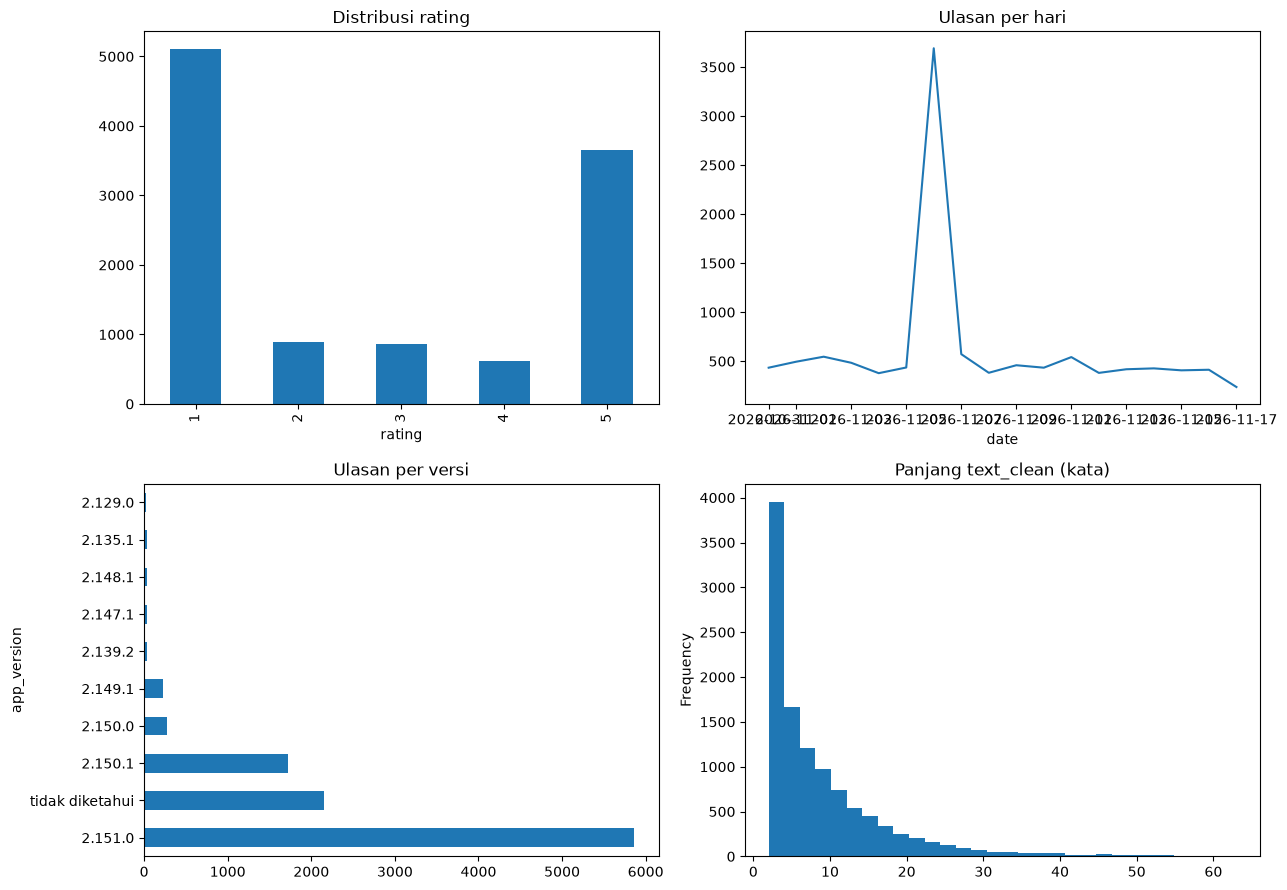

[('tidak', 6888), ('mau', 1568), ('error', 1483), ('padahal', 1412), ('masuk', 1290), ('transaksi', 1224), ('bagus', 1133), ('pakai', 1059), ('cicil', 1031), ('saldo', 1020), ('malah', 966), ('uang', 921), ('jaringan', 882), ('sering', 823), ('event', 794), ('gangguan', 747), ('buka', 692), ('akun', 574), ('jelas', 571), ('banyak', 571), ('lama', 560), ('membantu', 536), ('login', 531), ('makin', 487), ('sekarang', 480), ('selalu', 474), ('sama', 474), ('koneksi', 460), ('perbaiki', 459), ('mudah', 450)]
Jumlah akhir      : 11136
Rentang tanggal   : 2026-10-31 10:25:55 - 2026-11-17 16:12:10
Versi kosong (%)  : 19.4
Rating rata-rata  : 2.71
Median kata clean : 6.0


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

df["date"] = pd.to_datetime(df["date"])
df["n_words"] = df["text_clean"].str.split().str.len()

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. distribusi rating
df["rating"].value_counts().sort_index().plot(kind="bar", ax=ax[0, 0], title="Distribusi rating")

# 2. ulasan per hari
df.groupby(df["date"].dt.date).size().plot(ax=ax[0, 1], title="Ulasan per hari")

# 3. ulasan per versi (10 teratas)
df["app_version"].fillna("tidak diketahui").value_counts().head(10).plot(
    kind="barh", ax=ax[1, 0], title="Ulasan per versi")

# 4. panjang teks
df["n_words"].plot(kind="hist", bins=30, ax=ax[1, 1], title="Panjang text_clean (kata)")

plt.tight_layout()
os.makedirs("reports", exist_ok=True)
plt.savefig("reports/eda_overview.png", dpi=150)
plt.show()

# 5. kata terbanyak
cnt = Counter(w for t in df["text_clean"] for w in t.split())
print(cnt.most_common(30))

# 6. angka ringkasan untuk laporan
print("Jumlah akhir      :", len(df))
print("Rentang tanggal   :", df["date"].min(), "-", df["date"].max())
print("Versi kosong (%)  :", round(df["app_version"].isna().mean() * 100, 1))
print("Rating rata-rata  :", round(df["rating"].mean(), 2))
print("Median kata clean :", df["n_words"].median())

date
2026-11-06    3691
2026-11-07     572
2026-11-02     546
dtype: int64


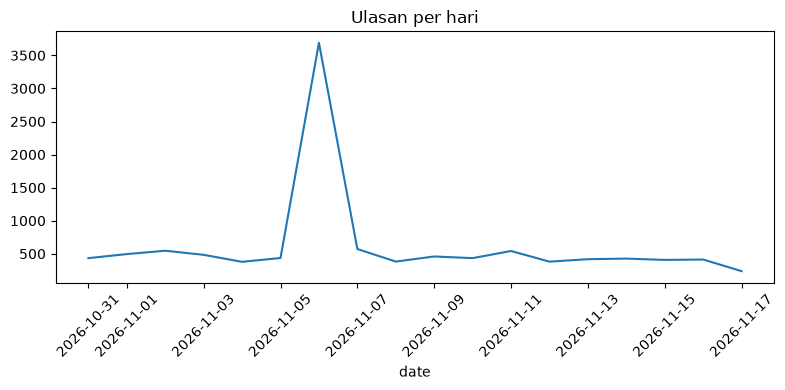

In [14]:
daily = df.groupby(df["date"].dt.date).size()
ax = daily.plot(title="Ulasan per hari", figsize=(8, 4))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/eda_per_hari.png", dpi=150)

print(daily.sort_values(ascending=False).head(3))   # tanggal lonjakan

In [16]:
spike = pd.to_datetime("2026-11-06").date()
df["is_spike"] = df["date"].dt.date == spike

cols = ["review_id", "text_raw", "text_norm", "text_clean", "text_stem",
        "rating", "date", "app_version", "thumbs_up", "is_spike"]
df[cols].to_csv("data/clean/reviews_clean.csv", index=False)
print(df.shape, df["is_spike"].sum())

sub = df[df["date"].dt.date == spike]
rest = df[df["date"].dt.date != spike]

print("Jumlah ulasan lonjakan:", len(sub))
print("Rating rata-rata lonjakan:", round(sub["rating"].mean(), 2))
print("Rating rata-rata hari lain:", round(rest["rating"].mean(), 2))
print("Versi dominan:", sub["app_version"].value_counts().head(3).to_dict())

print(Counter(w for t in sub["text_clean"] for w in t.split()).most_common(25))

# contoh ulasan asli
print(sub["text_raw"].sample(10, random_state=1).to_string())

(11136, 11) 3691
Jumlah ulasan lonjakan: 3691
Rating rata-rata lonjakan: 2.21
Rating rata-rata hari lain: 2.96
Versi dominan: {'2.151.0': 2348, '2.150.1': 152, '2.149.1': 42}
[('tidak', 2557), ('error', 848), ('jaringan', 726), ('masuk', 703), ('padahal', 701), ('gangguan', 611), ('mau', 550), ('sering', 504), ('bagus', 484), ('koneksi', 419), ('transaksi', 404), ('saldo', 392), ('internet', 372), ('login', 359), ('malah', 349), ('uang', 336), ('pakai', 317), ('buka', 274), ('perbaiki', 230), ('lancar', 226), ('terputus', 224), ('banyak', 213), ('sekarang', 205), ('lama', 198), ('sinyal', 195)]
6344    tolong dong masa dananya error, padahal mau na...
7313    ini dana kenapa selalu muncul koneksi internet...
5909    dana tolog perbaiki dana saya karena saat ingi...
7046    dana sering ganguan,, transaksi sering tergang...
5835    kenapa ya padahal udah topup dana pas udah top...
6094    kenapa dana mau me krim saldo Tidak bisa mau m...
5666    ini kenapa dana jangan lancar malah login 

In [17]:
chk = pd.read_csv("data/clean/reviews_clean.csv")
print(chk.shape)             # harus (11136, 10)
print(chk.columns.tolist())
print(chk.isna().sum())

(11136, 10)
['review_id', 'text_raw', 'text_norm', 'text_clean', 'text_stem', 'rating', 'date', 'app_version', 'thumbs_up', 'is_spike']
review_id         0
text_raw          0
text_norm         0
text_clean        0
text_stem         0
rating            0
date              0
app_version    2156
thumbs_up         0
is_spike          0
dtype: int64
